In [ ]:
import pandas as pd

# Load data
df_0 = pd.read_csv('../data/final_yc_extracted_features.csv')

# Keep rows without errors
df_clean = df_0[df_0['error'].isna()].copy()

# Save cleaned data
df_clean.to_csv('clean_data.csv', index=False)

df = pd.read_csv('clean_data.csv')

df_0.info()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7594 entries, 0 to 7593
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   company_name            7594 non-null   object
 1   industry                7594 non-null   object
 2   core_technology         7594 non-null   object
 3   product_type            7594 non-null   object
 4   target_audience         7594 non-null   object
 5   monetization_strategy   7594 non-null   object
 6   delivery_medium         7594 non-null   object
 7   value_proposition       7594 non-null   object
 8   regulatory_environment  7594 non-null   object
 9   unified_text            7594 non-null   object
 10  error                   249 non-null    object
 11  label                   7594 non-null   int64 
dtypes: int64(1), object(11)
memory usage: 712.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7345 entries, 0 to 7344
Data columns (total 12 columns):
 #   

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

def wilson_lower_bound(successes, total, z=1.96):
    if total == 0:
        return 0

    p_hat = successes / total

    numerator = (
        p_hat
        + (z**2 / (2 * total))
        - z * np.sqrt((p_hat * (1 - p_hat) / total) + (z**2 / (4 * total**2)))
    )

    denominator = 1 + (z**2 / total)

    return numerator / denominator


def get_useful_tags(df, cat_cols, label_col='label', min_samples=5):
    results = []

    # make sure label is numeric
    df = df.copy()
    df[label_col] = df[label_col].astype(int)

    for col in cat_cols:
        for tag in df[col].dropna().unique():
            tag_present = df[col] == tag

            a = ((tag_present) & (df[label_col] == 1)).sum()
            b = ((tag_present) & (df[label_col] == 0)).sum()
            c = ((~tag_present) & (df[label_col] == 1)).sum()
            d = ((~tag_present) & (df[label_col] == 0)).sum()

            total_present = a + b

            if total_present < min_samples:
                continue

            table = [[a, b], [c, d]]

            chi2, p_value, dof, expected = chi2_contingency(table)

            odds_ratio = ((a + 0.5) * (d + 0.5)) / ((b + 0.5) * (c + 0.5))
            success_rate = a / total_present
            wilson_score = wilson_lower_bound(a, total_present)

            results.append({
                'column': col,
                'tag': tag,
                'success_count': a,
                'fail_count': b,
                'total_present': total_present,
                'success_rate': success_rate,
                'p_value': p_value,
                'odds_ratio': odds_ratio,
                'wilson_lower_bound': wilson_score
            })

    tag_scores = pd.DataFrame(
        results,
        columns=[
            'column', 'tag', 'success_count', 'fail_count',
            'total_present', 'success_rate', 'p_value',
            'odds_ratio', 'wilson_lower_bound'
        ]
    )

    useful_tags = tag_scores[
        (tag_scores['p_value'] < 0.05) &
        (tag_scores['odds_ratio'] > 1)
    ].sort_values(by='wilson_lower_bound', ascending=False).reset_index(drop=True)

    return tag_scores, useful_tags

In [ ]:
df = pd.read_csv('clean_data.csv')

cat_cols = [

    'industry', 'core_technology', 'product_type', 'target_audience',

    'monetization_strategy', 'delivery_medium', 'value_proposition',

    'regulatory_environment'

]

drop_cols = ['label', 'company_name', 'unified_text', 'error']

tag_scores, useful_tags = get_useful_tags(df, cat_cols)

tag_scores.to_csv('all_tag_scores.csv', index=False)
useful_tags.to_csv('useful_tag_scores.csv', index=False)

df_filtered = df.copy()

for col in cat_cols:
    useful_values = useful_tags[useful_tags['column'] == col]['tag'].tolist()

    df_filtered[col] = df_filtered[col].apply(
        lambda x: x if x in useful_values else 'other_filtered'
    )

display(useful_tags.head(30))

,column,tag,success_count,fail_count,total_present,success_rate,p_value,odds_ratio,wilson_lower_bound
0,core_technology,hardware_and_robotics,318,0,318,1.000000,3.948883e-24,211.448024,0.988064
1,core_technology,other_unknown,2182,34,2216,0.984657,9.701597e-191,31.838987,0.978637
2,industry,industrials_and_manufacturing,521,5,526,0.990494,3.875981e-37,32.640180,0.977943
3,delivery_medium,hardware_device,305,2,307,0.993485,3.955538e-22,40.417601,0.976561
4,core_technology,data_and_cloud_infra,473,8,481,0.983368,6.894412e-32,18.963820,0.967527
5,regulatory_environment,financial_compliance,791,20,811,0.975339,1.582670e-51,13.917517,0.962216
6,regulatory_environment,healthcare_compliance,678,19,697,0.972740,9.664498e-43,12.261185,0.957818
7,monetization_strategy,transaction_fee,821,27,848,0.968160,1.217777e-50,10.791980,0.954071
8,product_type,managed_service,693,28,721,0.961165,9.225871e-40,8.556258,0.944445
9,product_type,other_unknown,652,26,678,0.961652,2.021392e-37,8.596129,0.944404


### Binary

In [ ]:
!pip install category_encoders -q
import pandas as pd
import category_encoders as ce

df = pd.read_csv('clean_data.csv')

cols_to_drop = ['unified_text', 'error']

df_safe_binary = df.drop(columns=cols_to_drop, errors='ignore')

cat_cols = [
    'industry', 'core_technology', 'product_type', 'target_audience',
    'monetization_strategy', 'delivery_medium', 'value_proposition',
    'regulatory_environment'
]
encoder = ce.BinaryEncoder(cols=cat_cols)

df_binary = encoder.fit_transform(df_safe_binary)

df_binary.to_csv('binary_encoded_data.csv', index=False)
print(f"binary_encoded_data.csv: {df_binary.shape}")

display(df_binary.head())

binary_encoded_data.csv: (7345, 27)


,company_name,industry_0,industry_1,industry_2,industry_3,core_technology_0,core_technology_1,core_technology_2,product_type_0,product_type_1,...,delivery_medium_0,delivery_medium_1,delivery_medium_2,value_proposition_0,value_proposition_1,value_proposition_2,regulatory_environment_0,regulatory_environment_1,regulatory_environment_2,label
0,CircuitHub,0,0,0,1,0,0,1,0,0,...,0,0,1,0,0,1,0,0,1,1
1,iCracked,0,0,1,0,0,1,0,0,0,...,0,0,1,0,1,0,0,0,1,1
2,42Floors,0,0,1,1,0,1,0,0,1,...,0,1,0,0,1,1,0,0,1,1
3,PlanGrid,0,0,0,1,0,1,1,0,1,...,0,1,1,1,0,0,0,0,1,1
4,WireOver,0,1,0,0,0,1,0,1,0,...,1,0,0,1,0,1,0,1,0,1


In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
import joblib

# 1. Prepare features (X) and target variable (y)
columns_to_drop = ['company_name', 'unified_text', 'error', 'label']
X_bin = df_binary.drop(columns=columns_to_drop, errors='ignore')
y_bin = df_binary['label']

# 2. Split into training and testing sets
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_bin,
    y_bin,
    test_size=0.2,
    random_state=42,
    stratify=y_bin
)

# 3. GridSearchCV Optimization for Random Forest
rf_bin = RandomForestClassifier(random_state=42, class_weight='balanced')

rf_param_grid_bin = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 8, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'max_features': ['sqrt', 'log2']
}

rf_grid_bin = GridSearchCV(
    estimator=rf_bin,
    param_grid=rf_param_grid_bin,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid_bin.fit(X_train_bin, y_train_bin)

print("Best Random Forest Parameters (Binary):")
print(rf_grid_bin.best_params_)

print("Best Random Forest CV Score (Binary):")
print(rf_grid_bin.best_score_)

# Save the GridSearchCV object and the best model directly after training
joblib.dump(rf_grid_bin, 'rf_grid_bin.joblib')
best_rf_bin = rf_grid_bin.best_estimator_
joblib.dump(best_rf_bin, 'best_rf_bin_model.joblib')

Best Random Forest Parameters (Binary):
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best Random Forest CV Score (Binary):
0.9196754957302071


['best_rf_bin_model.joblib']

================ Evaluation Metrics ================
Accuracy  : 0.9197
Precision : 0.9538
Recall    : 0.9401
F1-Score  : 0.9469
ROC-AUC   : 0.9634

Tuned Model Confusion Matrix (Binary):
[[ 299   51]
 [  67 1052]]


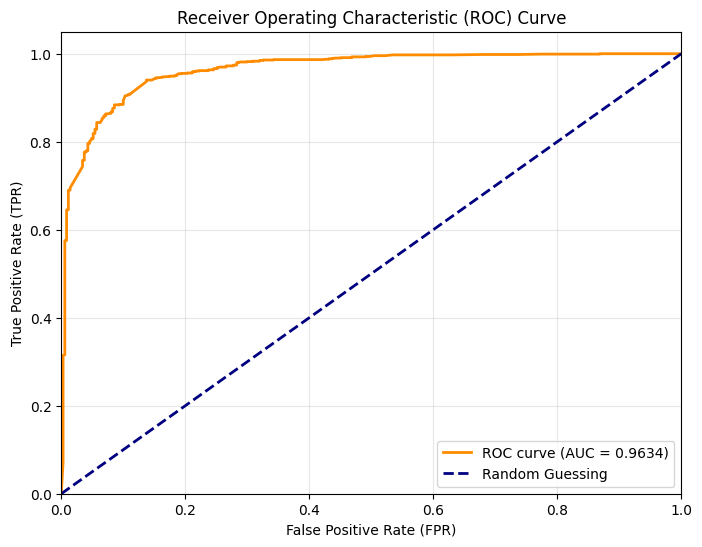

In [ ]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve, auc
)
import joblib
import matplotlib.pyplot as plt

# Load the best model saved from the previous step
loaded_best_rf_bin = joblib.load('best_rf_bin_model.joblib')

# Evaluate the loaded model on the test set
y_pred_bin = loaded_best_rf_bin.predict(X_test_bin)

# Get probabilities for class 1 to calculate ROC-AUC
y_pred_proba_bin = loaded_best_rf_bin.predict_proba(X_test_bin)[:, 1]

# Calculate all core metrics
accuracy_bin = accuracy_score(y_test_bin, y_pred_bin)
precision_bin = precision_score(y_test_bin, y_pred_bin)
recall_bin = recall_score(y_test_bin, y_pred_bin)
f1_bin = f1_score(y_test_bin, y_pred_bin)
roc_auc_bin = roc_auc_score(y_test_bin, y_pred_proba_bin)

# Print formatted results
print("================ Evaluation Metrics ================")
print(f"Accuracy  : {accuracy_bin:.4f}")
print(f"Precision : {precision_bin:.4f}")
print(f"Recall    : {recall_bin:.4f}")
print(f"F1-Score  : {f1_bin:.4f}")
print(f"ROC-AUC   : {roc_auc_bin:.4f}")
print("=========================================================\n")

print("Tuned Model Confusion Matrix (Binary):")
print(confusion_matrix(y_test_bin, y_pred_bin))
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test_bin, y_pred_proba_bin)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### One Hot

In [ ]:
import pandas as pd

df = pd.read_csv('clean_data.csv')

cat_cols = [
    'industry', 'core_technology', 'product_type', 'target_audience',
    'monetization_strategy', 'delivery_medium', 'value_proposition',
    'regulatory_environment'
]

cols_to_drop_early = ['unified_text', 'error']
df_safe_onehot = df.drop(columns=cols_to_drop_early, errors='ignore')

df_onehot = pd.get_dummies(
    df_safe_onehot,
    columns=cat_cols,
    drop_first=False
)

df_onehot.to_csv('onehot_encoded_data.csv', index=False)
print(f"onehot_encoded_data.csv:{df_onehot.shape}")

onehot_encoded_data.csv:(7345, 51)


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

df_onehot = pd.read_csv('onehot_encoded_data.csv')

y = df_onehot['label']

X = df_onehot.drop(columns=['label', 'company_name', 'unified_text', 'error'], errors='ignore')
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
rf_onehot = RandomForestClassifier(random_state=42, class_weight='balanced')

rf_param_grid_onehot = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 8, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'max_features': ['sqrt', 'log2']
}

rf_grid_onehot = GridSearchCV(
    estimator=rf_onehot,
    param_grid=rf_param_grid_onehot,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid_onehot.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid_onehot.best_params_)

print("Best Random Forest CV Score:")
print(rf_grid_onehot.best_score_)

# Save the GridSearchCV object and the best model directly after training
joblib.dump(rf_grid_onehot, 'rf_grid_onehot.joblib')
best_rf_onehot = rf_grid_onehot.best_estimator_
joblib.dump(best_rf_onehot, 'best_rf_onehot_model.joblib')

Best Random Forest Parameters:
{'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best Random Forest CV Score:
0.9227378781299755


['best_rf_onehot_model.joblib']

================ Evaluation Metrics ================
Accuracy  : 0.9224
Precision : 0.9564
Recall    : 0.9410
F1-Score  : 0.9486
ROC-AUC   : 0.9647

Tuned Model Classification Report (One-Hot):
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       350
           1       0.96      0.94      0.95      1119

    accuracy                           0.92      1469
   macro avg       0.89      0.90      0.89      1469
weighted avg       0.92      0.92      0.92      1469

Tuned Model Confusion Matrix (One-Hot):
[[ 302   48]
 [  66 1053]]


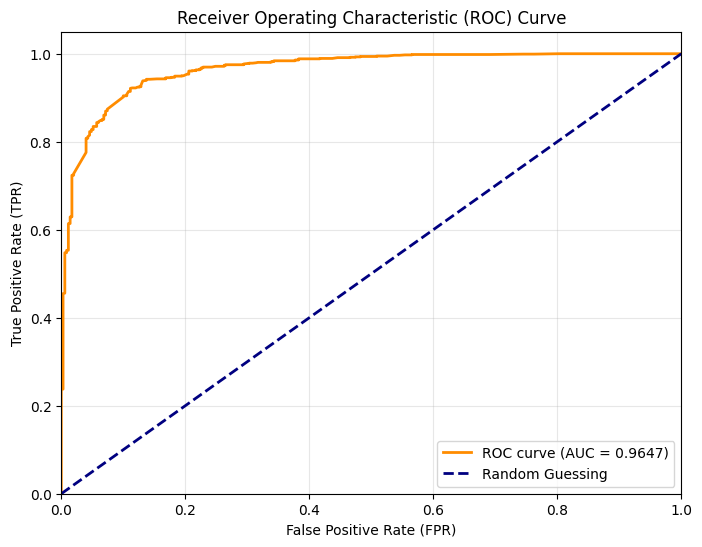

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc
)
import joblib

loaded_best_rf_onehot = joblib.load('best_rf_onehot_model.joblib')

y_pred_onehot = loaded_best_rf_onehot.predict(X_test)
y_pred_proba_onehot = loaded_best_rf_onehot.predict_proba(X_test)[:, 1]

accuracy_onehot = accuracy_score(y_test, y_pred_onehot)
precision_onehot = precision_score(y_test, y_pred_onehot)
recall_onehot = recall_score(y_test, y_pred_onehot)
f1_onehot = f1_score(y_test, y_pred_onehot)
roc_auc_onehot = roc_auc_score(y_test, y_pred_proba_onehot)

print("================ Evaluation Metrics ================")
print(f"Accuracy  : {accuracy_onehot:.4f}")
print(f"Precision : {precision_onehot:.4f}")
print(f"Recall    : {recall_onehot:.4f}")
print(f"F1-Score  : {f1_onehot:.4f}")
print(f"ROC-AUC   : {roc_auc_onehot:.4f}")
print("=========================================================\n")

print("Tuned Model Classification Report (One-Hot):")
print(classification_report(y_test, y_pred_onehot))

print("Tuned Model Confusion Matrix (One-Hot):")
print(confusion_matrix(y_test, y_pred_onehot))

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_onehot)
roc_auc_curve = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_curve:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
!pip install shap

In [ ]:
import pandas as pd
import numpy as np

# Using the macro categorical features you defined earlier for exact reverse matching
cat_cols = [
    'industry', 'core_technology', 'product_type', 'target_audience',
    'monetization_strategy', 'delivery_medium', 'value_proposition',
    'regulatory_environment'
]

detail_records = []

# Iterate through all One-Hot encoded features
for i, col in enumerate(X_encoded.columns):
    # 1. Calculate the global magnitude (absolute impact)
    mean_abs_shap = np.abs(shap_values_success[:, i]).mean()

    # 2. Extract direction: find samples where this feature is 1 (active)
    is_active = (X_encoded[col] == 1)

    if is_active.sum() > 0:
        # Calculate the average SHAP value (with sign) when the feature is active
        direction_shap = shap_values_success[is_active, i].mean()
    else:
        direction_shap = 0

    # Define direction labels
    if direction_shap > 0:
        direction_label = "Positive (+)"
    elif direction_shap < 0:
        direction_label = "Negative (-)"
    else:
        direction_label = "Neutral"

    # 3. Exact reverse mapping: use your defined cat_cols list
    original_feature = col
    for cat in cat_cols:
        # If the column starts with 'original_feature_', assign it to that parent feature
        if col.startswith(cat + '_'):
            original_feature = cat
            break

    detail_records.append({
        'Original Feature': original_feature,
        'Encoded Sub-Feature': col,
        'Absolute Impact (Magnitude)': mean_abs_shap,
        'Net Impact when Active (Direction)': direction_shap,
        'Impact Direction': direction_label
    })

df_detail = pd.DataFrame(detail_records)

# 4. Aggregate total importance for the original feature (sum of absolute impacts of its sub-features)
df_original = df_detail.groupby('Original Feature')['Absolute Impact (Magnitude)'].sum().reset_index()
df_original.columns = ['Original Feature', 'Total Original Feature Impact']

# 5. Merge the total impact back to the details table and apply dual-level sorting
df_final = pd.merge(df_detail, df_original, on='Original Feature', how='left')
df_final = df_final.sort_values(
    by=['Total Original Feature Impact', 'Absolute Impact (Magnitude)'],
    ascending=[False, False]
).reset_index(drop=True)

# 6. Reorder columns for better readability
columns_order = [
    'Original Feature', 'Total Original Feature Impact',
    'Encoded Sub-Feature', 'Absolute Impact (Magnitude)',
    'Net Impact when Active (Direction)', 'Impact Direction'
]
df_final = df_final[columns_order]

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

display(df_final)

# Save to local CSV
df_final.to_csv('shap_comprehensive_analysis.csv', index=False)
print("\n[Success] Comprehensive analysis report saved to 'shap_comprehensive_analysis.csv'")

,Original Feature,Total Original Feature Impact,Encoded Sub-Feature,Absolute Impact (Magnitude),Net Impact when Active (Direction),Impact Direction
0,core_technology,0.161352,core_technology_ai_ml,0.100946,1.302554e-15,Positive (+)
1,core_technology,0.161352,core_technology_other_unknown,0.051998,7.757032e-16,Positive (+)
2,core_technology,0.161352,core_technology_data_and_cloud_infra,0.006046,5.864159e-17,Positive (+)
3,core_technology,0.161352,core_technology_hardware_and_robotics,0.002020,4.080419e-17,Positive (+)
4,core_technology,0.161352,core_technology_blockchain_web3,0.000309,-1.439431e-17,Negative (-)
5,core_technology,0.161352,core_technology_iot,0.000032,-2.478176e-18,Negative (-)
6,industry,0.124300,industry_other_unknown,0.080845,9.436896e-16,Positive (+)
7,industry,0.124300,industry_enterprise_software,0.016645,4.860420e-16,Positive (+)
8,industry,0.124300,industry_healthcare_and_biotech,0.008300,1.580833e-16,Positive (+)
9,industry,0.124300,industry_fintech,0.007899,1.386156e-16,Positive (+)



[Success] Comprehensive analysis report saved to 'shap_comprehensive_analysis.csv'
